# Birliktelik Kuralı Madenciliği

## Apriori, FP-Growth ve ECLAT | Veri Madenciliği Uygulaması

Bu uygulamada **aynı biyolojik örnekte yüksek ifade işareti taşıyan gen adlarını** kullanacağız.

**Veri:** 400 temsili biyolojik örnek, 30 gen. Her örnek bir “sepet”, genler ise sepetin öğeleridir.

**Önemli:** Veri tamamen **sentetiktir**, bir makaleden veya hasta grubundan alınmamıştır. Birlikte görülme örüntülerini öğrenmeyi kolaylaştırmak için oluşturulmuştur. Gen adları gerçek, örnekler ve ilişkiler kurgusaldır. Sonuçlar biyolojik etkileşim, hastalık ilişkisi veya klinik öneri kanıtı değildir.


## 1. Kütüphaneleri Hazırlama
Apriori ve FP-Growth için `mlxtend` kullanacağız. ECLAT'ı işlem kimliği kümelerinin kesişimiyle açıklayan küçük bir fonksiyon yazacağız.


In [1]:
%pip -q install "mlxtend==0.23.4"

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from pathlib import Path
from time import perf_counter
import math

import warnings
warnings.filterwarnings("ignore")

## 2. Biyolojik Örneği “Sepet” Olarak Düşünme

| Alışveriş analizi | Bu uygulama |
|---|---|
| Alışveriş işlemi | Bir temsili biyolojik örnek |
| Sepetteki ürünler | O örnekte yüksek ifade işareti taşıyan genler |
| Ürün var/yok | Yüksek ifade işareti var/yok |
| Süt ⇒ Yoğurt | RAD51 ⇒ PALB2 gibi temsili bir kural |

**1:** Yüksek ifade işareti var. **0:** Yüksek ifade işareti yok.

## 3. Gen İsimlerini Tanımlama


In [7]:
gen_gruplari = [
    ["BRCA1", "BRCA2", "RAD51", "PALB2", "ATM"],
    ["EGFR", "ERBB2", "KRAS", "BRAF", "MAPK1"],
    ["TP53", "MDM2", "CDKN1A", "RB1", "CDKN2A"],
    ["IL6", "TNF", "IL1B", "STAT3", "NFKB1"]
]

ek_genler = ["APOE", "VEGFA", "ESR1", "AKT1", "PTEN",
             "MYC", "GATA3", "FOXP3", "CXCL8", "BCL2"]

tum_genler = sorted([gen for grup in gen_gruplari for gen in grup] + ek_genler)
print("Toplam gen sayısı:", len(tum_genler))

Toplam gen sayısı: 30


### Veri Üretme Mantığı
Her örnek için:
1. Her genin %3 olasılıkla rastgele işaretlenmesine izin verilir.
2. Dört örüntü grubunun her biri bağımsız olarak belirli bir olasılıkla seçilir.
3. Seçilen gruptaki her gen %88 olasılıkla listeye eklenir.

Bir örnekte birden fazla grup seçilebilir. Bazı örnekler hiçbir gen içermeyebilir; bunları da örnek sayısına dahil ederiz.

Bu olasılıklar biyolojik oranlar değildir. Birliktelikleri **bilerek oluşturduğumuz eğitim ayarlarıdır**. Sabit rastgelelik tohumu sayesinde aynı veriyi yeniden üretebiliriz.

In [9]:
rng = np.random.default_rng(42)
ornek_sayisi = 400
grup_olasiliklari = [0.30, 0.26, 0.24, 0.22]

gen_listeleri = []

for i in range(ornek_sayisi):
    # set, aynı genin bir örnekte iki kez sayılmasını önler.
    secilen_genler = set()

    # Düşük olasılıklı rastgele işaretler.
    for gen in tum_genler:
        if rng.random() < 0.03:
            secilen_genler.add(gen)

    # Birlikte görülmesi beklenen yapay örüntüler.
    for grup, olasilik in zip(gen_gruplari, grup_olasiliklari):
        if rng.random() < olasilik:
            for gen in grup:
                if rng.random() < 0.88:
                    secilen_genler.add(gen)

    gen_listeleri.append(sorted(secilen_genler))

print("Oluşturulan örnek:", len(gen_listeleri))
for i, liste in enumerate(gen_listeleri[:10], start=1):
    print(f"Örnek {i:03d}:", liste)

Oluşturulan örnek: 400
Örnek 001: []
Örnek 002: ['KRAS']
Örnek 003: ['IL6', 'PALB2', 'RAD51']
Örnek 004: ['CDKN2A', 'MDM2', 'RB1', 'TP53']
Örnek 005: ['BCL2']
Örnek 006: ['CDKN1A', 'CDKN2A', 'MDM2', 'RAD51', 'RB1', 'TP53']
Örnek 007: ['CDKN1A', 'MDM2']
Örnek 008: ['ATM', 'BRAF', 'BRCA1', 'BRCA2', 'EGFR', 'ERBB2', 'IL6', 'MAPK1', 'PALB2', 'RAD51']
Örnek 009: []
Örnek 010: ['ATM', 'BRCA1', 'BRCA2', 'PALB2', 'RAD51']


### Listeleri Tablo Olarak Görüntüleme


In [11]:
ornek_idleri = [f"ORNEK_{i:03d}" for i in range(1, ornek_sayisi + 1)]
liste_df = pd.DataFrame({"Ornek_ID": ornek_idleri, "Gen_Listesi": gen_listeleri})
liste_df["Gen_Sayisi"] = liste_df["Gen_Listesi"].apply(len)
display(liste_df.head(12))
print("Boş gen listesi olan örnek:", (liste_df["Gen_Sayisi"] == 0).sum())
print("Örnek başına ortalama işaretli gen:", round(liste_df["Gen_Sayisi"].mean(), 2))

,Ornek_ID,Gen_Listesi,Gen_Sayisi
0,ORNEK_001,[],0
1,ORNEK_002,[KRAS],1
2,ORNEK_003,"[IL6, PALB2, RAD51]",3
3,ORNEK_004,"[CDKN2A, MDM2, RB1, TP53]",4
4,ORNEK_005,[BCL2],1
5,ORNEK_006,"[CDKN1A, CDKN2A, MDM2, RAD51, RB1, TP53]",6
6,ORNEK_007,"[CDKN1A, MDM2]",2
7,ORNEK_008,"[ATM, BRAF, BRCA1, BRCA2, EGFR, ERBB2, IL6, MAPK1, PALB2, RAD51]",10
8,ORNEK_009,[],0
9,ORNEK_010,"[ATM, BRCA1, BRCA2, PALB2, RAD51]",5


Boş gen listesi olan örnek: 51
Örnek başına ortalama işaretli gen: 5.4


## 4. Gen Listelerinden 0–1 Matrisi Oluşturma
`TransactionEncoder`, her gen için bir sütun açar. Bir örneğin listesinde o gen varsa True, yoksa False yazar. Daha sonra bunları 1 ve 0'a dönüştürürüz.

**Satır:** biyolojik örnek. **Sütun:** gen. Örnek kimliği analiz girdisi değildir.

In [14]:
encoder = TransactionEncoder()
matris = encoder.fit(gen_listeleri).transform(gen_listeleri)

df = pd.DataFrame(matris, columns=encoder.columns_, index=ornek_idleri)
# Hiç seçilmemiş bir gen olsa bile 30 sütunluk yapıyı koru.
df = df.reindex(columns=tum_genler, fill_value=False).astype(int)
df.index.name = "Ornek_ID"

print("Matris boyutu:", df.shape)
df.head(7)

Matris boyutu: (400, 30)


,AKT1,APOE,ATM,BCL2,BRAF,BRCA1,...,RAD51,RB1,STAT3,TNF,TP53,VEGFA
Ornek_ID,,,,,,,,,,,,,
ORNEK_001,0,0,0,0,0,0,...,0,0,0,0,0,0
ORNEK_002,0,0,0,0,0,0,...,0,0,0,0,0,0
ORNEK_003,0,0,0,0,0,0,...,1,0,0,0,0,0
ORNEK_004,0,0,0,0,0,0,...,0,1,0,0,1,0
ORNEK_005,0,0,0,1,0,0,...,0,0,0,0,0,0
ORNEK_006,0,0,0,0,0,0,...,1,1,0,0,1,0
ORNEK_007,0,0,0,0,0,0,...,0,0,0,0,0,0


### Veri Kontrolü
Eksik değer olmamalı ve bütün hücreler 0 veya 1 olmalıdır. Algoritmalara boolean (True/False) gösterimi vereceğiz; bu, aynı 0–1 bilgisini taşır.

In [15]:
print("Eksik hücre sayısı:", df.isna().sum().sum())
print("Görülen değerler:", np.unique(df.to_numpy()))
print("Bütün değerler 0 veya 1 mi?", df.isin([0, 1]).all().all())

veri_bool = df.astype(bool)
display(veri_bool.iloc[:5, :8])

Eksik hücre sayısı: 0
Görülen değerler: [0 1]
Bütün değerler 0 veya 1 mi? True


,AKT1,APOE,ATM,BCL2,BRAF,BRCA1,BRCA2,CDKN1A
Ornek_ID,,,,,,,,
ORNEK_001,False,False,False,False,False,False,False,False
ORNEK_002,False,False,False,False,False,False,False,False
ORNEK_003,False,False,False,False,False,False,False,False
ORNEK_004,False,False,False,False,False,False,False,False
ORNEK_005,False,False,False,True,False,False,False,False


## 5. Genlerin Görülme Sıklığı
Bir genin sütun toplamı, işaretlendiği örnek sayısını verir. Sütun ortalaması ise o genin desteğidir.

,Ornek_Sayisi,Destek
PALB2,141,0.352
BRCA2,131,0.328
RAD51,128,0.320
BRCA1,128,0.320
ATM,122,0.305
KRAS,111,0.278
EGFR,107,0.268
ERBB2,105,0.262
BRAF,102,0.255
MAPK1,96,0.240


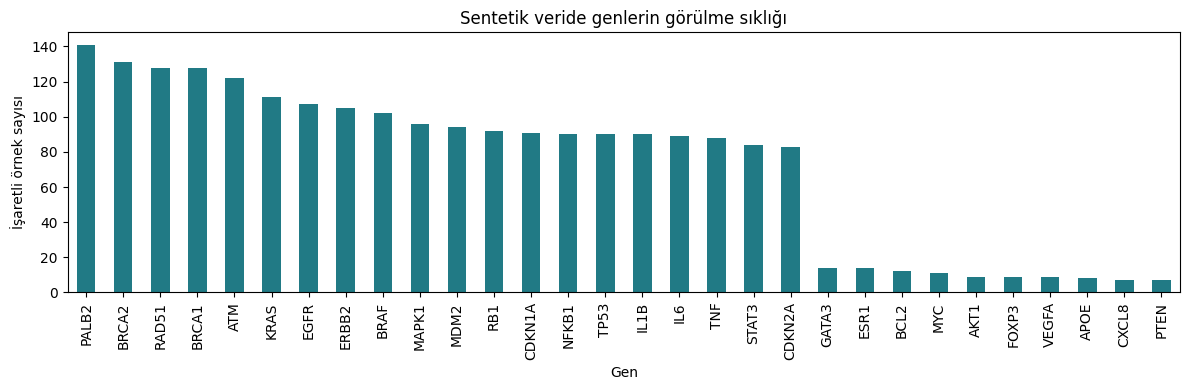

In [16]:
gen_ozet = pd.DataFrame({
    "Ornek_Sayisi": df.sum(),
    "Destek": df.mean()
}).sort_values("Ornek_Sayisi", ascending=False)

display(gen_ozet.round(3))
gen_ozet["Ornek_Sayisi"].plot.bar(figsize=(12, 4), color="#217A85")
plt.ylabel("İşaretli örnek sayısı")
plt.xlabel("Gen")
plt.title("Sentetik veride genlerin görülme sıklığı")
plt.tight_layout()
plt.show()

### Matrisin Küçük Bir Bölümünü Görselleştirme
Bütün matris 400 × 30 boyutundadır. Okunabilirlik için ilk 40 örneği gösteriyoruz. Grafikteki birlikte görülen renkli hücreler olası örüntüler hakkında ilk fikir verir.

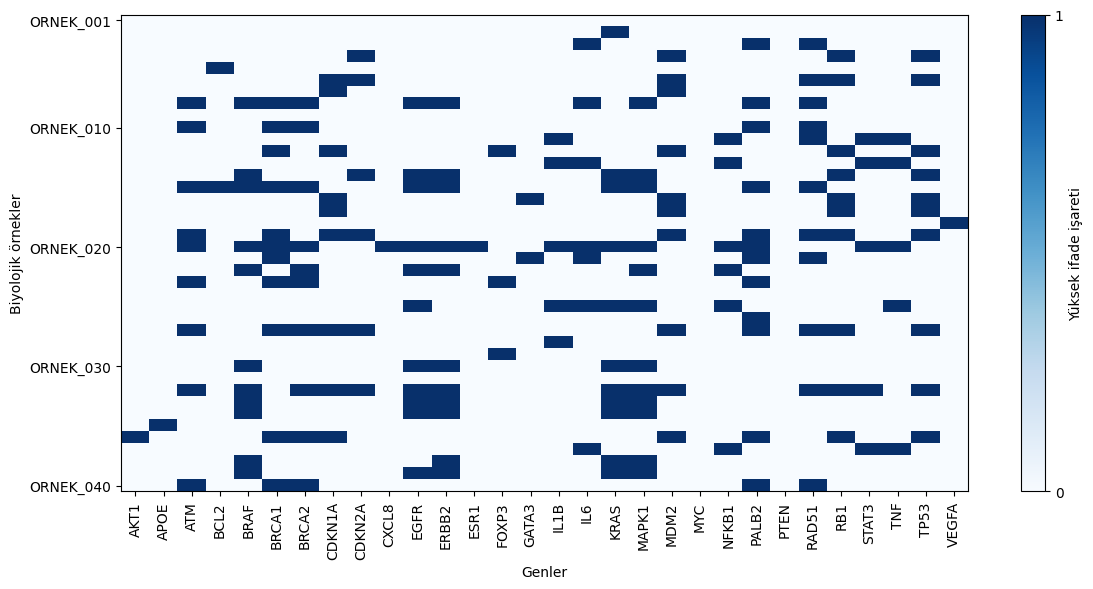

In [17]:
plt.figure(figsize=(12, 6))
plt.imshow(df.iloc[:40], cmap="Blues", aspect="auto", vmin=0, vmax=1,
           interpolation="nearest")
plt.xticks(range(df.shape[1]), df.columns, rotation=90)
plt.yticks([0, 9, 19, 29, 39], df.index[[0, 9, 19, 29, 39]])
plt.xlabel("Genler")
plt.ylabel("Biyolojik örnekler")
plt.colorbar(ticks=[0, 1], label="Yüksek ifade işareti")
plt.tight_layout()
plt.show()

## 6. Destek, Güven ve Lift: Elle Hesaplama
Örnek kuralımız **RAD51 ⇒ PALB2** olsun.

$$Destek(X\Rightarrow Y)=\frac{n(X\cup Y)}{N}$$
$$Güven(X\Rightarrow Y)=\frac{n(X\cup Y)}{n(X)}$$
$$Lift(X\Rightarrow Y)=\frac{Güven(X\Rightarrow Y)}{Destek(Y)}$$

Destek, bütün örneklerdeki birlikte görülme oranıdır. Güven, X işaretliyken Y'nin de işaretlenme oranıdır. Lift, bu oranı Y'nin genel görülme oranıyla karşılaştırır. Lift > 1 pozitif birliktelik, = 1 bağımsızlık beklentisi, < 1 negatif birliktelik yönünde yorumlanır. Bu ölçüler nedensellik veya istatistiksel anlamlılık testi değildir.

In [18]:
X_gen = "RAD51"
Y_gen = "PALB2"

N = len(df)
X_sayisi = df[X_gen].sum()
Y_sayisi = df[Y_gen].sum()
birlikte_sayisi = ((df[X_gen] == 1) & (df[Y_gen] == 1)).sum()

destek = birlikte_sayisi / N
guven = birlikte_sayisi / X_sayisi
lift = guven / (Y_sayisi / N)

print(f"Kural: {X_gen} => {Y_gen}")
print(f"Toplam örnek: {N}")
print(f"X: {X_sayisi}, Y: {Y_sayisi}, birlikte: {birlikte_sayisi}")
print(f"Destek: {destek:.3f} (%{100 * destek:.1f})")
print(f"Güven: {guven:.3f} (%{100 * guven:.1f})")
print(f"Lift: {lift:.3f}")

Kural: RAD51 => PALB2
Toplam örnek: 400
X: 128, Y: 141, birlikte: 111
Destek: 0.278 (%27.8)
Güven: 0.867 (%86.7)
Lift: 2.460


## 7. Üç Yöntem İçin Ortak Ayarlar
- **Minimum destek = 0.10:** En az 40 örnekte görülen kümeler.
- **Minimum güven = 0.70:** Öncülü içeren örneklerin en az %70'inde sonuç da bulunmalı.
- **Minimum lift = 1.50:** Genel sıklığa göre en az 1.5 kat görülme.
- **En fazla 3 gen:** Hesaplama ve kural sayısını ders için yönetilebilir tutar.

Bu eşikler evrensel biyolojik sınırlar değildir. Aynı veriyi ve aynı eşikleri kullanırsak üç yöntem aynı sık kümeleri bulmalıdır. Bunlar sınıflandırıcı değildir; doğruluk yarışı yapmıyoruz.

In [24]:
MIN_DESTEK = 0.10
MIN_GUVEN = 0.70
MIN_LIFT = 1.50
MAX_GEN = 3

print("Minimum örnek sayısı:", math.ceil(MIN_DESTEK * len(df)))

Minimum örnek sayısı: 40


## 8. Apriori ile Sık Gen Kümeleri
Apriori önce tekli genleri sayar, ardından sık genlerden daha büyük adaylar oluşturur. Sık olmayan bir kümenin üst kümelerini eler.

`max_len=3`, en fazla üç gen içeren kümeleri arar. `use_colnames=True`, sonuçlarda gen adlarını gösterir.

In [25]:
baslangic = perf_counter()
sik_apriori = apriori(veri_bool, min_support=MIN_DESTEK,
                       use_colnames=True, max_len=MAX_GEN)
sure_apriori = perf_counter() - baslangic

sik_apriori["Gen_Sayisi"] = sik_apriori["itemsets"].apply(len)
print("Bulunan sık küme:", len(sik_apriori))
display(sik_apriori.sort_values("support", ascending=False).head(15))

Bulunan sık küme: 106


,support,itemsets,Gen_Sayisi
14,0.3525,(PALB2),1
3,0.3275,(BRCA2),1
15,0.3200,(RAD51),1
2,0.3200,(BRCA1),1
0,0.3050,(ATM),1
35,0.2850,"(PALB2, BRCA2)",2
31,0.2800,"(PALB2, BRCA1)",2
10,0.2775,(KRAS),1
63,0.2775,"(PALB2, RAD51)",2
22,0.2750,"(PALB2, ATM)",2


### Apriori Kümelerinden Kural Üretme
Sık küme bulma ve kural üretme iki ayrı adımdır. `association_rules` sık kümelerden kuralları üretir. Önce güven eşiğini, sonra lift eşiğini uygularız.

Bir kuralın öncülü veya sonucu birden fazla gen içerebilir. Örneğin `{BRCA1, RAD51} ⇒ {PALB2}`.

In [26]:
kurallar_apriori = association_rules(
    sik_apriori[["support", "itemsets"]],
    metric="confidence", min_threshold=MIN_GUVEN
)
kurallar_apriori = kurallar_apriori[
    kurallar_apriori["lift"] >= MIN_LIFT
].copy()

print("Filtrelerden geçen kural:", len(kurallar_apriori))
display(kurallar_apriori[["antecedents", "consequents", "support",
                          "confidence", "lift"]].head(10))

Filtrelerden geçen kural: 299


,antecedents,consequents,support,confidence,lift
0,(BRCA1),(ATM),0.2625,0.820312,2.689549
1,(ATM),(BRCA1),0.2625,0.860656,2.689549
2,(BRCA2),(ATM),0.2650,0.809160,2.652985
3,(ATM),(BRCA2),0.2650,0.868852,2.652985
4,(PALB2),(ATM),0.2750,0.780142,2.557842
5,(ATM),(PALB2),0.2750,0.901639,2.557842
6,(ATM),(RAD51),0.2525,0.827869,2.587090
7,(RAD51),(ATM),0.2525,0.789062,2.587090
8,(BRAF),(EGFR),0.2125,0.833333,3.115265
9,(EGFR),(BRAF),0.2125,0.794393,3.115265


### Kural Tablosunu Okunabilir Hâle Getirme
Kütüphane kümeleri `frozenset` olarak saklar. Aşağıdaki yardımcı fonksiyon yalnızca **gösterimi** düzenler. Hesaplamaları değiştirmez.

In [27]:
def kural_tablosu(kurallar):
    tablo = kurallar[["antecedents", "consequents", "support",
                       "confidence", "lift"]].copy()
    tablo["antecedents"] = tablo["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    tablo["consequents"] = tablo["consequents"].apply(lambda x: ", ".join(sorted(x)))
    tablo.columns = ["Oncul", "Sonuc", "Destek", "Guven", "Lift"]
    return tablo.sort_values(
        ["Lift", "Guven", "Destek", "Oncul", "Sonuc"],
        ascending=[False, False, False, True, True]
    ).reset_index(drop=True)

apriori_tablo = kural_tablosu(kurallar_apriori)
display(apriori_tablo.head(15).round(3))

,Oncul,Sonuc,Destek,Guven,Lift
0,"NFKB1, STAT3",TNF,0.162,0.929,4.221
1,TNF,"NFKB1, STAT3",0.162,0.739,4.221
2,"NFKB1, STAT3",IL1B,0.165,0.943,4.190
3,"IL1B, NFKB1",STAT3,0.165,0.880,4.190
4,STAT3,"IL1B, NFKB1",0.165,0.786,4.190
5,IL1B,"NFKB1, STAT3",0.165,0.733,4.190
6,"IL6, STAT3",IL1B,0.162,0.942,4.187
7,IL1B,"IL6, STAT3",0.162,0.722,4.187
8,"IL1B, IL6",STAT3,0.162,0.878,4.183
9,"IL1B, TNF",STAT3,0.162,0.878,4.183


## 9. FP-Growth ile Aynı Analiz
FP-Growth, ortak öğe başlangıçlarını sık örüntü ağacında toplar ve koşullu örüntüleri araştırır. Apriori gibi büyük aday listeleri üretme yaklaşımını kullanmaz.

Aynı veri, minimum destek ve maksimum küme uzunluğunu kullanıyoruz.

In [28]:
baslangic = perf_counter()
sik_fp = fpgrowth(veri_bool, min_support=MIN_DESTEK,
                   use_colnames=True, max_len=MAX_GEN)
sure_fp = perf_counter() - baslangic

kurallar_fp = association_rules(sik_fp, metric="confidence", min_threshold=MIN_GUVEN)
kurallar_fp = kurallar_fp[kurallar_fp["lift"] >= MIN_LIFT].copy()

print("Sık küme:", len(sik_fp), "Kural:", len(kurallar_fp))
display(kural_tablosu(kurallar_fp).head(15).round(3))

Sık küme: 106 Kural: 299


,Oncul,Sonuc,Destek,Guven,Lift
0,"NFKB1, STAT3",TNF,0.162,0.929,4.221
1,TNF,"NFKB1, STAT3",0.162,0.739,4.221
2,"NFKB1, STAT3",IL1B,0.165,0.943,4.190
3,"IL1B, NFKB1",STAT3,0.165,0.880,4.190
4,STAT3,"IL1B, NFKB1",0.165,0.786,4.190
5,IL1B,"NFKB1, STAT3",0.165,0.733,4.190
6,"IL6, STAT3",IL1B,0.162,0.942,4.187
7,IL1B,"IL6, STAT3",0.162,0.722,4.187
8,"IL1B, IL6",STAT3,0.162,0.878,4.183
9,"IL1B, TNF",STAT3,0.162,0.878,4.183


## 10. ECLAT: Genlerin Örnek Listelerini Kesiştirme
ECLAT, her genin bulunduğu örneklerin kimliklerini saklar. İki genin listelerinin kesişimi, ikisinin birlikte bulunduğu örnekleri verir.

Python'daki `set` bir kümedir. `&` iki kümenin kesişimini hesaplar. Önce bir çift gen üzerinde görelim.

In [29]:
ornek_kumeleri = {}
for gen in df.columns:
    ornek_kumeleri[gen] = set(df.index[df[gen] == 1])

rad51_ornekleri = ornek_kumeleri["RAD51"]
palb2_ornekleri = ornek_kumeleri["PALB2"]
ortak_ornekler = rad51_ornekleri & palb2_ornekleri

print("RAD51 işaretli örnek:", len(rad51_ornekleri))
print("PALB2 işaretli örnek:", len(palb2_ornekleri))
print("Kesişim:", len(ortak_ornekler))
print("Birlikte destek:", len(ortak_ornekler) / len(df))
print("İlk 10 ortak örnek:", sorted(ortak_ornekler)[:10])

RAD51 işaretli örnek: 128
PALB2 işaretli örnek: 141
Kesişim: 111
Birlikte destek: 0.2775
İlk 10 ortak örnek: ['ORNEK_003', 'ORNEK_008', 'ORNEK_010', 'ORNEK_015', 'ORNEK_019', 'ORNEK_021', 'ORNEK_027', 'ORNEK_040', 'ORNEK_042', 'ORNEK_043']


### Küçük Bir ECLAT Fonksiyonu
Fonksiyonun mantığı:
1. Sık tek genlerle başla.
2. Bir gen ekleyerek kümeyi büyüt.
3. Örnek listelerini kesiştir.
4. Destek yeterliyse sonucu kaydet ve büyütmeye devam et.

`tara`, kendisini çağıran küçük bir yardımcı fonksiyondur (**özyineleme**). Bu hücreyi hazır bir araç gibi de kullanabilirsiniz. Esas fikir `ortak = kimlikler & diger_kimlikler` satırındadır.

Bu kod, öğretim için sadeleştirilmiş ECLAT uygulamasıdır. En fazla üç genlik kümeleri tarar.

In [30]:
def eclat(veri, min_destek=0.10, max_gen=3):
    n = len(veri)
    min_sayi = math.ceil(min_destek * n)
    dikey = []

    for gen in sorted(veri.columns):
        kimlikler = set(veri.index[veri[gen] == 1])
        if len(kimlikler) >= min_sayi:
            dikey.append((gen, kimlikler))

    sonuclar = []

    def tara(onek, adaylar):
        for i, (gen, kimlikler) in enumerate(adaylar):
            yeni_kume = onek + [gen]
            sonuclar.append({"support": len(kimlikler) / n,
                             "itemsets": frozenset(yeni_kume)})

            if len(yeni_kume) < max_gen:
                yeni_adaylar = []
                for diger_gen, diger_kimlikler in adaylar[i + 1:]:
                    ortak = kimlikler & diger_kimlikler
                    if len(ortak) >= min_sayi:
                        yeni_adaylar.append((diger_gen, ortak))
                tara(yeni_kume, yeni_adaylar)

    tara([], dikey)
    return pd.DataFrame(sonuclar, columns=["support", "itemsets"])

In [31]:
baslangic = perf_counter()
sik_eclat = eclat(df, min_destek=MIN_DESTEK, max_gen=MAX_GEN)
sure_eclat = perf_counter() - baslangic

kurallar_eclat = association_rules(sik_eclat, metric="confidence", min_threshold=MIN_GUVEN)
kurallar_eclat = kurallar_eclat[kurallar_eclat["lift"] >= MIN_LIFT].copy()

print("Sık küme:", len(sik_eclat), "Kural:", len(kurallar_eclat))
display(kural_tablosu(kurallar_eclat).head(15).round(3))

Sık küme: 106 Kural: 299


,Oncul,Sonuc,Destek,Guven,Lift
0,"NFKB1, STAT3",TNF,0.162,0.929,4.221
1,TNF,"NFKB1, STAT3",0.162,0.739,4.221
2,"NFKB1, STAT3",IL1B,0.165,0.943,4.190
3,"IL1B, NFKB1",STAT3,0.165,0.880,4.190
4,STAT3,"IL1B, NFKB1",0.165,0.786,4.190
5,IL1B,"NFKB1, STAT3",0.165,0.733,4.190
6,"IL6, STAT3",IL1B,0.162,0.942,4.187
7,IL1B,"IL6, STAT3",0.162,0.722,4.187
8,"IL1B, IL6",STAT3,0.162,0.878,4.183
9,"IL1B, TNF",STAT3,0.162,0.878,4.183


## 11. Üç Yöntemi Karşılaştırma
Aynı sık kümelerden, aynı ölçütlerle aynı kurallar üretilmelidir. Sonuç tablosunun satır sırası farklı olabilir.

Süreler yalnızca **bu çalıştırmanın gözlemidir**. Kütüphane uygulamaları ile sade Python ECLAT kodunun bu küçük veri üzerindeki süreleri, genel bir hız sıralaması veya bilimsel benchmark değildir.

In [32]:
karsilastirma = pd.DataFrame({
    "Yontem": ["Apriori", "FP-Growth", "ECLAT"],
    "Sik_Kume_Sayisi": [len(sik_apriori), len(sik_fp), len(sik_eclat)],
    "Kural_Sayisi": [len(kurallar_apriori), len(kurallar_fp), len(kurallar_eclat)],
    "Sik_Kume_Arama_Suresi_sn": [sure_apriori, sure_fp, sure_eclat]
})
display(karsilastirma.round(4))

# Sıralamadan bağımsız, hem kümeleri hem desteklerini karşılaştır.
kontrol = pd.concat([
    sik_apriori.set_index("itemsets")["support"].rename("Apriori"),
    sik_fp.set_index("itemsets")["support"].rename("FP_Growth"),
    sik_eclat.set_index("itemsets")["support"].rename("ECLAT")
], axis=1)

ayni_kumeler = not kontrol.isna().any().any()
ayni_destekler = ayni_kumeler and np.allclose(kontrol["Apriori"], kontrol["FP_Growth"]) and np.allclose(kontrol["Apriori"], kontrol["ECLAT"])
print("Sık kümeler ve destekler aynı mı?", ayni_destekler)

# Kuralları ve ölçülerini, ortak bir sıralama kullanarak kontrol et.
sirali_tablolar = [kural_tablosu(k).sort_values(["Oncul", "Sonuc"]).reset_index(drop=True)
                    for k in [kurallar_apriori, kurallar_fp, kurallar_eclat]]
for tablo in sirali_tablolar[1:]:
    pd.testing.assert_frame_equal(sirali_tablolar[0], tablo, check_exact=False)
print("Kurallar ve ölçüleri de aynı.")

,Yontem,Sik_Kume_Sayisi,Kural_Sayisi,Sik_Kume_Arama_Suresi_sn
0,Apriori,106,299,0.0083
1,FP-Growth,106,299,0.1206
2,ECLAT,106,299,0.0063


Sık kümeler ve destekler aynı mı? True
Kurallar ve ölçüleri de aynı.


## 12. Önce Basit, Tek Genden Tek Gene Kuralları İnceleyelim
Birden fazla gen içeren kurallar ilk okumada zor olabilir. Önce tek genlik öncül ve tek genlik sonuç içeren kuralları seçelim.

Kuralların desteği, güveni ve lift değeri birlikte yorumlanmalıdır. Çok yüksek lift, düşük örnek sayısıyla elde edilmişse tek başına güvenilirlik sağlamaz.

In [33]:
tekli_kurallar = kurallar_apriori[
    (kurallar_apriori["antecedents"].apply(len) == 1) &
    (kurallar_apriori["consequents"].apply(len) == 1)
].copy()

tekli_tablo = kural_tablosu(tekli_kurallar)
display(tekli_tablo.head(15).round(3))

,Oncul,Sonuc,Destek,Guven,Lift
0,STAT3,IL1B,0.180,0.857,3.810
1,IL1B,STAT3,0.180,0.800,3.810
2,TNF,NFKB1,0.188,0.852,3.788
3,NFKB1,TNF,0.188,0.833,3.788
4,STAT3,TNF,0.175,0.833,3.788
5,TNF,STAT3,0.175,0.795,3.788
6,CDKN1A,TP53,0.192,0.846,3.761
7,TP53,CDKN1A,0.192,0.856,3.761
8,CDKN2A,MDM2,0.182,0.880,3.743
9,MDM2,CDKN2A,0.182,0.777,3.743


### Bulunan Bir Kuralı Cümleyle Açıklama
Aşağıdaki hücre en yüksek liftli tekli kuralı seçer ve sayıları doğrudan matristen yeniden hesaplar. Böylece kütüphane çıktısını nasıl okuyacağımızı görürüz.

In [35]:
if len(tekli_tablo) > 0:
    ilk = tekli_tablo.iloc[0]
    x = ilk["Oncul"]
    y = ilk["Sonuc"]
    n_x = int(df[x].sum())
    n_xy = int(((df[x] == 1) & (df[y] == 1)).sum())

    print(f"Örnek kural: {x} => {y}")
    print(f"{x}, {n_x} örnekte işaretlidir; bunların {n_xy} tanesinde {y} de işaretlidir.")
    print(f"Bütün örneklerin %{100 * ilk['Destek']:.1f} tanesinde ikisi birlikte işaretlidir.")
    print(f"Güven %{100 * ilk['Guven']:.1f}; lift {ilk['Lift']:.2f}.")
    print("Bu sonuç, tasarladığımız sentetik örüntüyü gösterir.")
else:
    print("Bu eşiklerde tekli kural bulunamadı. Eşikleri gözden geçirin.")

Örnek kural: STAT3 => IL1B
STAT3, 84 örnekte işaretlidir; bunların 72 tanesinde IL1B de işaretlidir.
Bütün örneklerin %18.0 tanesinde ikisi birlikte işaretlidir.
Güven %85.7; lift 3.81.
Bu sonuç, tasarladığımız sentetik örüntüyü gösterir.


## 13. Kuralları Görselleştirme
İlk grafikte en yüksek liftli 10 tekli kuralı görüyoruz. İkinci grafikte tüm filtrelenmiş kuralların destek–güven ilişkisini, renklerle de lift değerini gösteriyoruz.

Grafikler kural ölçülerini karşılaştırır; klinik başarı veya neden–sonuç göstermez.

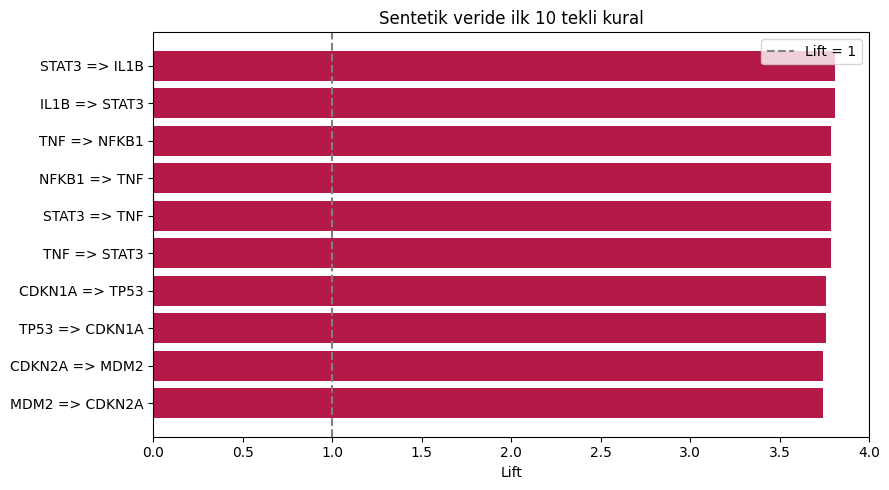

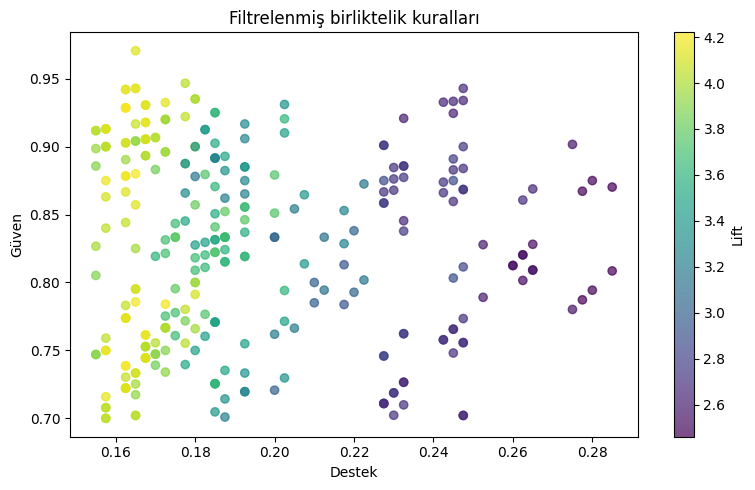

In [36]:
if len(tekli_tablo) > 0:
    ilk10 = tekli_tablo.head(10).iloc[::-1]
    etiketler = ilk10["Oncul"] + " => " + ilk10["Sonuc"]
    plt.figure(figsize=(9, 5))
    plt.barh(etiketler, ilk10["Lift"], color="#B41948")
    plt.axvline(1, color="gray", linestyle="--", label="Lift = 1")
    plt.xlabel("Lift")
    plt.title("Sentetik veride ilk 10 tekli kural")
    plt.legend()
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(kurallar_apriori["support"], kurallar_apriori["confidence"],
            c=kurallar_apriori["lift"], cmap="viridis", alpha=0.7)
plt.xlabel("Destek")
plt.ylabel("Güven")
plt.colorbar(label="Lift")
plt.title("Filtrelenmiş birliktelik kuralları")
plt.tight_layout()
plt.show()

## 14. Eşikler Değişirse Ne Olur?
Minimum desteği artırınca daha az sayıda sık küme bekleriz. Bu hücre yalnızca küme sayısını gösterir; aynı güven ve lift filtrelerinden sonraki kural sayısını hesaplamaz.

Öğrenciler 0.05, 0.10 ve 0.20 değerlerini karşılaştırsın. Nadir fakat güçlü birlikte görülen genler yüksek destek eşiğinde kaybolabilir.

In [37]:
esik_sonuclari = []
for esik in [0.05, 0.10, 0.20]:
    sonuc = fpgrowth(veri_bool, min_support=esik,
                     use_colnames=True, max_len=MAX_GEN)
    esik_sonuclari.append({"Min_Destek": esik,
                           "En_Az_Ornek": math.ceil(esik * len(df)),
                           "Sik_Kume_Sayisi": len(sonuc)})
display(pd.DataFrame(esik_sonuclari))

,Min_Destek,En_Az_Ornek,Sik_Kume_Sayisi
0,0.05,20,603
1,0.10,40,106
2,0.20,80,52


## Not:

**Gerçek Biyolojik Veriye Geçiş ve Kaynaklar**

Bu uygulamada makaleden veri aktarımı yapılmadı. Veriyi sınıf içinde anlaşılır ve tamamen yeniden üretilebilir tutmak için sentetik örnekler kullanıldı.

Gerçek bir gen ifade matrisiyle çalışırken ölçüm türü, normalizasyon ve “yüksek ifade” eşiği gerekçelendirilmelidir. Mutasyon var/yok tablosu ile ifade yüksek/düşük tablosu farklı biyolojik anlamlar taşır. Örnek grubu, teknik partiler ve karıştırıcı değişkenler birlikte görülme ilişkileri üretebilir. Keşfedilen ilişkiler bağımsız veride ayrıca değerlendirilmelidir.

**Teknik kaynaklar:**
- [mlxtend: Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/)
- [mlxtend: FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/)
- [mlxtend: Association Rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/)

Not: ECLAT, bu notebook içinde işlem kimliği kesişimlerini kullanan sade bir eğitim uygulaması olarak yazılmıştır. Araştırma düzeyinde performans karşılaştırması amaçlamaz.